# LSTM Stock Price Prediction
A standalone, executable Google Colab notebook. Run all cells in order on a CPU runtime. The included real AAPL snapshot permits an offline experiment after installing packages. Optional Yahoo data is an explicit alternative, never a silent fallback.

Inspired by [Syed-Waheed/stock-price-prediction-lstm](https://github.com/Syed-Waheed/stock-price-prediction-lstm). This implementation uses smaller stacked LSTMs and a separate validation period. Educational use; no investment advice.

In [1]:
# Install only if the pinned workflow is not already available (e.g. fresh Colab).
import importlib.util
if importlib.util.find_spec('tensorflow') is None or importlib.util.find_spec('yfinance') is None:
    %pip install -q tensorflow-cpu==2.18.1 pandas==2.2.3 numpy==2.0.2 scikit-learn==1.6.1 matplotlib==3.10.1 yfinance==0.2.65


## 1. Historical data and provenance
The embedded CSV is the unmodified `finance-charts-apple.csv` from https://github.com/plotly/datasets (downloaded 2026-10-29). We use `AAPL.Close`, the historical nominal USD close, not the adjusted column. This is a small 2015–2017 demonstration, not current market evidence. Corporate actions, data revisions and data-use terms matter for other datasets.

In [2]:
import base64, gzip
from pathlib import Path
Path('data').mkdir(exist_ok=True)
Path('data/aapl_history.csv').write_bytes(gzip.decompress(base64.b64decode('...')))
CSV = 'data/aapl_history.csv'
TICKER = 'AAPL'

## 2. Optional Yahoo Finance data
Leave disabled to reproduce the included experiment. Yahoo requires network access and may rate limit requests. Adjusted Yahoo prices differ from the embedded nominal prices. Changing data defines a new experiment; do not compare its scores as if it were the same run.

In [3]:
USE_YAHOO = False
if USE_YAHOO:
    import yfinance as yf
    import pandas as pd
    TICKER = 'AAPL'  # e.g. 'RELIANCE.NS'; change units in plots/docs accordingly
    raw = yf.download(TICKER, start='2015-01-01', end='2025-01-01', auto_adjust=True, progress=False)
    if raw.empty:
        raise RuntimeError('Yahoo returned no data; check access/ticker; no fallback was used.')
    close = raw['Close']
    if isinstance(close, pd.DataFrame): close = close.iloc[:, 0]
    pd.DataFrame({'Date': close.index, 'Close': close.to_numpy()}).to_csv('data/yahoo.csv', index=False)
    CSV = 'data/yahoo.csv'


## 3. Method and reusable pipeline
Predict the next observed trading day's close from the previous 20 observed closes. Chronological raw-row splits are 70% training, 15% validation and 15% test. Fit MinMaxScaler **only** on training rows; held-out values may lie outside [0,1]. Windows never include their target. Validation/test windows may use earlier observed closes, including earlier held-out dates: this is rolling one-step evaluation, not a forecast of the whole test period from a single origin.

Architecture: LSTM(32, return_sequences=True) → LSTM(16) → Dense(1), Adam and scaled MSE. Early stopping selects weights using validation loss only; test data is untouched until final evaluation. Fixed seed and deterministic TensorFlow operations aid reproducibility but hardware/library changes can change results.

In [4]:
"""Chronological one-step stock forecasting. No test-set model selection."""
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')
import argparse
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def load_prices(path):
    df = pd.read_csv(path)
    df = df.rename(columns={'AAPL.Close': 'Close'})
    if not {'Date', 'Close'} <= set(df):
        raise ValueError('CSV must contain Date and Close columns')
    df = df[['Date', 'Close']].copy()
    df['Date'] = pd.to_datetime(df.Date, errors='raise')
    df['Close'] = pd.to_numeric(df.Close, errors='raise')
    if df.Date.duplicated().any() or df.isna().any().any():
        raise ValueError('Missing values and duplicate dates are not accepted')
    if not np.isfinite(df.Close).all() or (df.Close <= 0).any():
        raise ValueError('Prices must be finite and positive')
    return df.sort_values('Date').reset_index(drop=True)


def prepare(df, lookback=20):
    n = len(df)
    a, b = int(n * .7), int(n * .85)
    if lookback < 1 or a <= lookback or b-a < 2 or n-b < 2:
        raise ValueError('Insufficient observations for lookback and 70/15/15 split')
    values = df.Close.to_numpy().reshape(-1, 1)
    scaler = MinMaxScaler().fit(values[:a])
    scaled = scaler.transform(values).astype('float32')
    targets = np.arange(lookback, n)
    x = np.stack([scaled[i-lookback:i] for i in targets])
    y = scaled[targets]
    masks = {'train': targets < a, 'validation': (targets >= a) & (targets < b), 'test': targets >= b}
    splits = {name: (x[m], y[m], targets[m]) for name, m in masks.items()}
    return scaler, splits, (a, b)


def evaluate(actual, predicted, previous):
    actual, predicted, previous = map(lambda v: np.asarray(v).reshape(-1), (actual, predicted, previous))
    if not (len(actual) == len(predicted) == len(previous)) or len(actual) < 2:
        raise ValueError('Metrics require aligned arrays with at least two rows')
    if not all(np.isfinite(v).all() for v in (actual, predicted, previous)):
        raise ValueError('Metrics require finite values')
    mse = mean_squared_error(actual, predicted)
    return {'MSE': float(mse), 'RMSE': float(np.sqrt(mse)),
            'MAE': float(mean_absolute_error(actual, predicted)),
            'R2': float(r2_score(actual, predicted)),
            'DirectionalAccuracy': float(np.mean(np.sign(actual-previous) == np.sign(predicted-previous)))}


def build_model(lookback):
    import tensorflow as tf
    model = tf.keras.Sequential([tf.keras.Input((lookback, 1)),
        tf.keras.layers.LSTM(32, return_sequences=True),
        tf.keras.layers.LSTM(16), tf.keras.layers.Dense(1)])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss='mse')
    return model


def dataset(x, y, batch_size=32):
    import tensorflow as tf
    ds = tf.data.Dataset.from_tensor_slices((x, y)).batch(batch_size)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return ds.with_options(options)


def run(csv='data/aapl_history.csv', output='artifacts', epochs=40, lookback=20, ticker='AAPL', seed=42):
    import tensorflow as tf
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    if epochs < 1:
        raise ValueError('epochs must be positive')
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    df = load_prices(csv)
    scaler, splits, bounds = prepare(df, lookback)
    model = build_model(lookback)
    train, val = splits['train'], splits['validation']
    history = model.fit(dataset(*train[:2]), validation_data=dataset(*val[:2]), epochs=epochs, shuffle=False,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)], verbose=0)
    out = Path(output)
    out.mkdir(parents=True, exist_ok=True)
    metric_rows, prediction_rows = [], []
    for split in ('validation', 'test'):
        x, _, idx = splits[split]
        prediction = scaler.inverse_transform(model(x, training=False).numpy()).ravel()
        actual = df.Close.to_numpy()[idx]
        previous = df.Close.to_numpy()[idx-1]
        for name, pred in [('LSTM', prediction), ('Naive', previous)]:
            metric_rows.append({'Split': split, 'Model': name, **evaluate(actual, pred, previous)})
        prediction_rows.append(pd.DataFrame({'Date': df.Date.iloc[idx].dt.strftime('%Y-%m-%d').to_numpy(),
            'Ticker': ticker, 'Split': split, 'Actual': actual, 'PreviousClose': previous,
            'LSTM': prediction, 'Naive': previous,
            'LSTMAbsoluteError': abs(actual-prediction), 'NaiveAbsoluteError': abs(actual-previous),
            'ActualDirection': np.sign(actual-previous), 'LSTMDirection': np.sign(prediction-previous),
            'NaiveDirection': np.zeros(len(idx), dtype=int)}))
    metrics = pd.DataFrame(metric_rows)
    predictions = pd.concat(prediction_rows, ignore_index=True)
    metrics.to_csv(out/'metrics.csv', index=False)
    predictions.to_csv(out/'power_bi_predictions.csv', index=False)
    pd.DataFrame(history.history).rename_axis('EpochZeroBased').to_csv(out/'training_history.csv')
    model.save(out/'model.keras')
    (out/'scaler.json').write_text(json.dumps({'min': scaler.min_.tolist(), 'scale': scaler.scale_.tolist(),
        'data_min': scaler.data_min_.tolist(), 'data_max': scaler.data_max_.tolist()} , indent=2))
    meta = {'ticker': ticker, 'seed': seed, 'lookback': lookback, 'requested_epochs': epochs,
        'completed_epochs': len(history.history['loss']), 'best_epoch': int(np.argmin(history.history['val_loss'])+1),
        'rows': len(df), 'split_boundaries': list(bounds),
        'date_range': [str(df.Date.min().date()), str(df.Date.max().date())],
        'sample_counts': {k: len(v[0]) for k,v in splits.items()},
        'data_sha256': hashlib.sha256(Path(csv).read_bytes()).hexdigest(),
        'tensorflow': tf.__version__, 'numpy': np.__version__,
        'protocol': 'Rolling one-step forecasts using observed previous closes; no recursive forecasts.'}
    (out/'run_metadata.json').write_text(json.dumps(meta, indent=2))
    fig, ax = plt.subplots(figsize=(10,4))
    ax.plot(df.Date, df.Close, label='Close')
    for i, label in zip(bounds, ['Validation starts', 'Test starts']): ax.axvline(df.Date.iloc[i], linestyle='--', label=label)
    ax.set(title=f'{ticker}: chronological split', ylabel='Price (historical USD)'); ax.legend(); fig.tight_layout(); fig.savefig(out/'data_split.png'); plt.close(fig)
    fig, ax = plt.subplots(figsize=(10,4))
    for k in ['loss','val_loss']: ax.plot(np.arange(1,len(history.history[k])+1),history.history[k], label=k)
    ax.set(xlabel='Epoch', ylabel='Scaled MSE', title='Learning curves'); ax.legend(); fig.tight_layout(); fig.savefig(out/'training.png'); plt.close(fig)
    test = predictions[predictions.Split == 'test']
    fig, ax = plt.subplots(figsize=(10,4))
    for k in ['Actual','LSTM','Naive']: ax.plot(pd.to_datetime(test.Date),test[k], label=k)
    ax.set(title='Untouched test period: one-step predictions', ylabel='Price (historical USD)'); ax.legend(); fig.tight_layout(); fig.savefig(out/'test_predictions.png'); plt.close(fig)
    fig, ax = plt.subplots(figsize=(10,4))
    for k in ['LSTM','Naive']: ax.hist(test.Actual-test[k], bins=20, alpha=.5, label=k)
    ax.set(title='Test residuals', xlabel='Actual minus predicted (USD)'); ax.legend(); fig.tight_layout(); fig.savefig(out/'residuals.png'); plt.close(fig)
    print(metrics.to_string(index=False))
    return metrics, predictions, meta




## 4. Train once, evaluate, and export
The naive baseline predicts tomorrow's price equals today's price. Report MSE (price²), RMSE and MAE (price), R² (can be negative), and directional accuracy (fraction in [0,1]). Direction compares sign(predicted − previous close) with sign(actual − previous close), including zero as a distinct outcome. A flat naive forecast therefore scores only on unchanged days. High R² on price levels is not trading profitability. Test scores must not guide repeated tuning.

In [5]:
metrics, predictions, metadata = run(CSV, output='artifacts', epochs=40, lookback=20, ticker=TICKER)
display(metrics)
display(predictions.head())
print(metadata)

     Split Model       MSE     RMSE      MAE       R2  DirectionalAccuracy
validation  LSTM  8.353565 2.890253 2.447223 0.753001             0.486842
validation Naive  1.987980 1.409957 0.939737 0.941219             0.000000
      test  LSTM 29.615397 5.442003 4.271295 0.480147             0.407895
      test Naive  1.729928 1.315267 0.820395 0.969634             0.013158


,Split,Model,MSE,RMSE,MAE,R2,DirectionalAccuracy
0,validation,LSTM,8.353565,2.890253,2.447223,0.753001,0.486842
1,validation,Naive,1.987980,1.409957,0.939737,0.941219,0.000000
2,test,LSTM,29.615397,5.442003,4.271295,0.480147,0.407895
3,test,Naive,1.729928,1.315267,0.820395,0.969634,0.013158


,Date,Ticker,Split,Actual,PreviousClose,LSTM,Naive,LSTMAbsoluteError,NaiveAbsoluteError,ActualDirection,LSTMDirection,NaiveDirection
0,2016-07-13,AAPL,validation,96.870003,97.419998,99.652641,97.419998,2.782638,0.549995,-1.0,1.0,0
1,2016-07-14,AAPL,validation,98.790001,96.870003,99.742294,96.870003,0.952293,1.919998,1.0,1.0,0
2,2016-07-15,AAPL,validation,98.779999,98.790001,99.864090,98.790001,1.084091,0.010002,-1.0,1.0,0
3,2016-07-18,AAPL,validation,99.830002,98.779999,100.015434,98.779999,0.185432,1.050003,1.0,1.0,0
4,2016-07-19,AAPL,validation,99.870003,99.830002,100.219238,99.830002,0.349235,0.040001,1.0,1.0,0


{'ticker': 'AAPL', 'seed': 42, 'lookback': 20, 'requested_epochs': 40, 'completed_epochs': 13, 'best_epoch': 6, 'rows': 506, 'split_boundaries': [354, 430], 'date_range': ['2015-02-17', '2017-02-16'], 'sample_counts': {'train': 334, 'validation': 76, 'test': 76}, 'data_sha256': '24c7604edfd5afe862ddb9f9535e2fd7351f43711bfc442bca52055e15e37bcd', 'tensorflow': '2.18.1', 'numpy': '2.0.2', 'protocol': 'Rolling one-step forecasts using observed previous closes; no recursive forecasts.'}


## 5. Graphs: split, learning curves, test forecasts, residuals

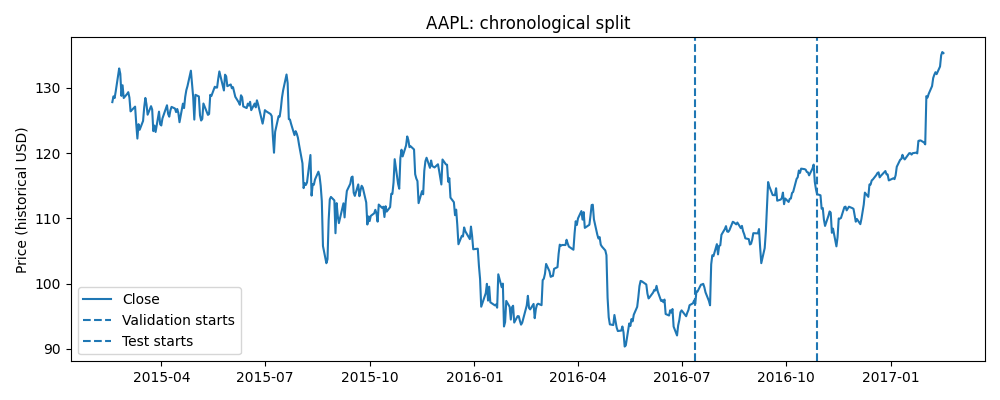

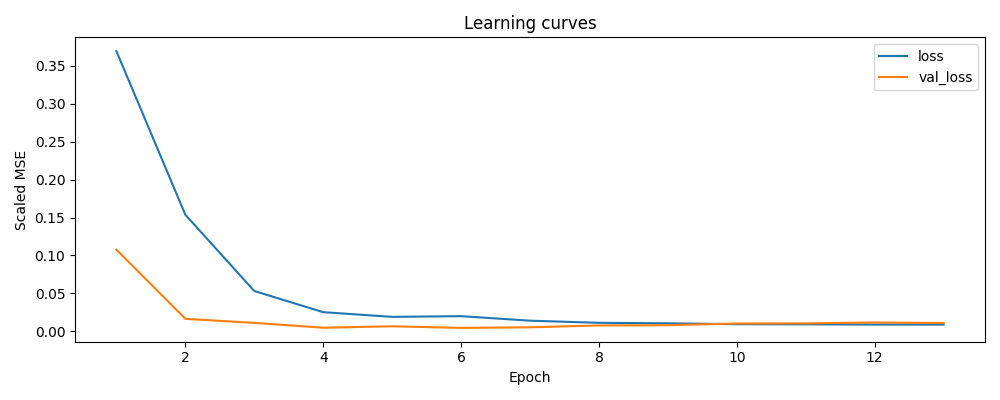

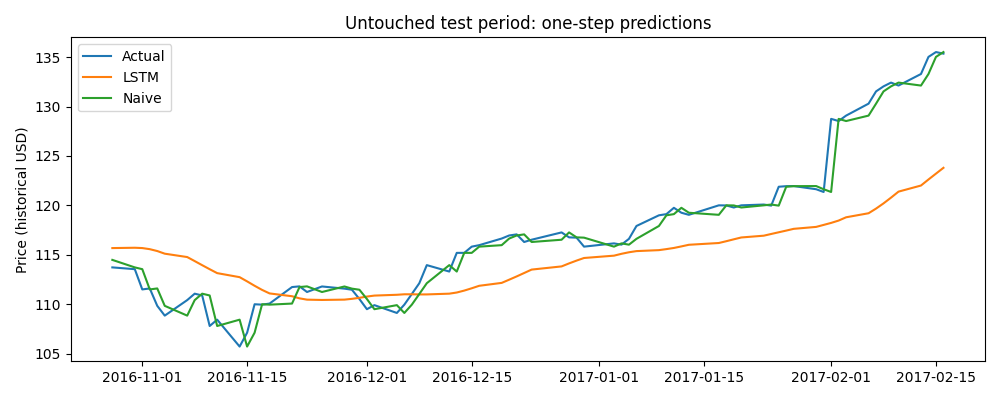

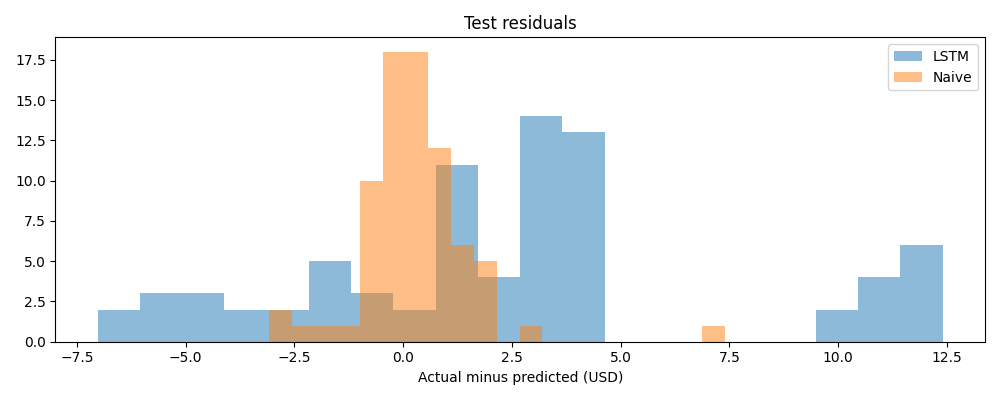

In [6]:
from IPython.display import Image, display
for name in ['data_split', 'training', 'test_predictions', 'residuals']:
    display(Image(filename=f'artifacts/{name}.png'))

## 6. Power BI and downloads
Import `power_bi_predictions.csv` with Date as Date and prices as Decimal Number. Filter Split to test. Use Date as a continuous line axis and Actual/LSTM/Naive as values. Import `metrics.csv` separately and filter Split and Model for metric cards; do not sum per-run metrics. DirectionalAccuracy is a fraction; format as percent. No PBIX file is required. The export contains observed test targets: it is a retrospective evaluation dataset.

The ZIP includes the saved Keras model, scaler parameters, run metadata with data checksum, training history, metrics, predictions and four PNG graphs.

In [7]:
import shutil
shutil.make_archive('lstm_results', 'zip', 'artifacts')
try:
    from google.colab import files
    files.download('lstm_results.zip')
except ImportError:
    print('Saved lstm_results.zip in the current directory.')

Saved lstm_results.zip in the current directory.


## 7. Interpretation and limitations
Compare test RMSE/MAE with persistence before claiming value. If LSTM loses, report that result. A small single-stock sample, regime changes, price-level nonstationarity, corporate-action handling and seed variability limit generalization. No transaction costs, execution simulation, exogenous features or production monitoring are modeled. Future work: walk-forward evaluation, training-only tuning, returns targets, multiple seeds and cost-aware backtests. None is evidence of profitability until measured.

### Interview questions
1. **Why LSTM?** Its gates can retain temporal information; this does not guarantee an advantage over persistence.
2. **Why no shuffled split?** Future information must not influence earlier forecasts.
3. **Where is scaling fitted?** Training rows only; validation/test are transformed without refitting.
4. **What does return_sequences do?** It passes one hidden output per time step to the next LSTM layer.
5. **Why separate validation and test?** Validation chooses stopping weights; the test estimates held-out performance once.
6. **Why a naive baseline?** Stock price levels are persistent; a sophisticated model must demonstrate added value.
7. **Is R² accuracy?** No. It measures squared-error reduction relative to a constant mean, not a percentage of correct forecasts.
8. **How is direction measured?** Compare both predicted and actual changes against the same previous observed close.
9. **Does prior test context leak?** Observed earlier closes are valid for rolling one-step forecasts, but not for multi-step forecasts made at the start of the test period.
10. **Why can a scaled test value exceed one?** Prices can exceed the training range; clipping would conceal that information.
11. **How does early stopping help?** It restores the validation-best weights and reduces unnecessary fitting, without guaranteeing generalization.
12. **Can this be traded directly?** No; predictive evaluation omits costs, risk constraints, execution delays and robust backtesting.